# [Lab Session 2](otsu.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

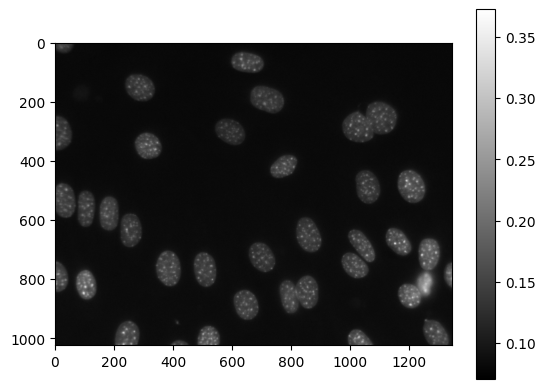

In [7]:
imgf =plt.imread('data/NIH3T3/im/dna-0.png')
plt.figure()
plt.imshow(imgf, cmap='grey')
plt.colorbar()

In [8]:
imgf.dtype

dtype('float32')

**[Task 1.2.]()** Quantify the image into 256 bins:

<BarContainer object of 256 artists>

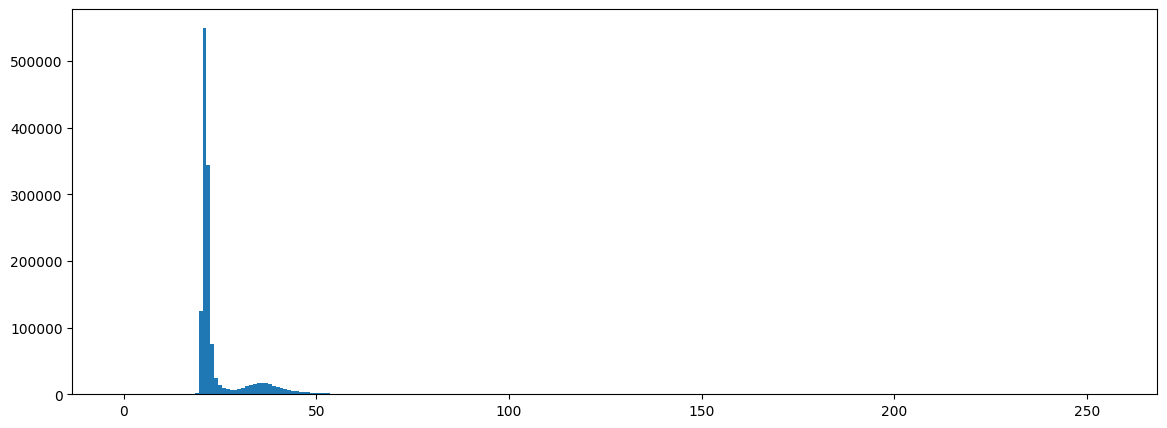

In [10]:
img8=(imgf*255).round().astype(np.uint8)

h=np.zeros(256) #flat array with 256 zeros

for i in range(256):
    h[i]=np.sum(img8 == i) # img8==i ist ein array, in dem die pixel mit intensität i True sind und die anderen False; mit np.sum() wird ihre summe (=häufigkeit) gezählz und als h[i] gespeichert
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

                      

In [11]:
img8.dtype

dtype('uint8')

**[Task 1.3.]()** Compute the image histogram:

Show the computed histogram:

<BarContainer object of 256 artists>

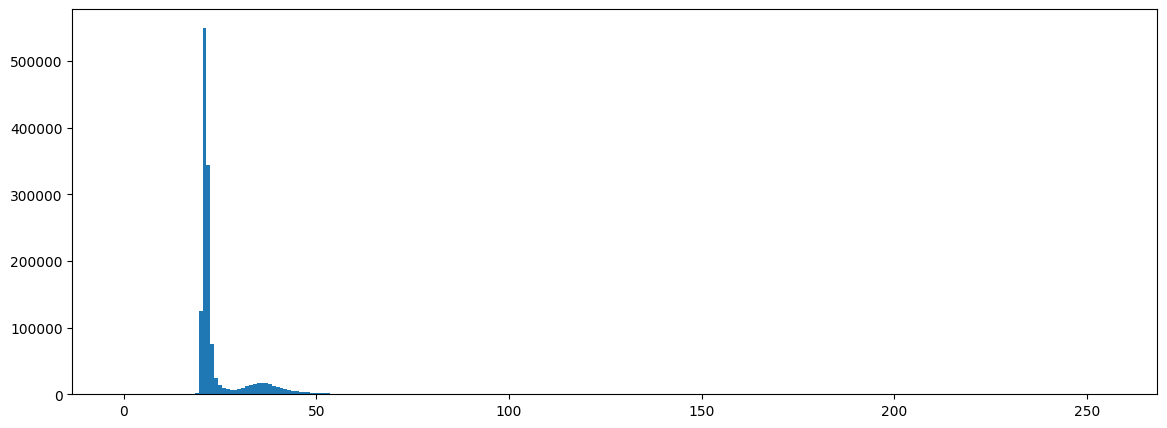

In [ ]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

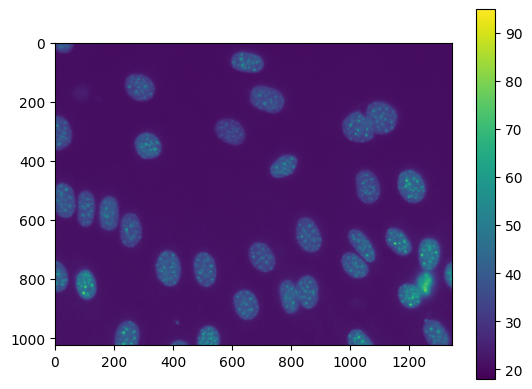

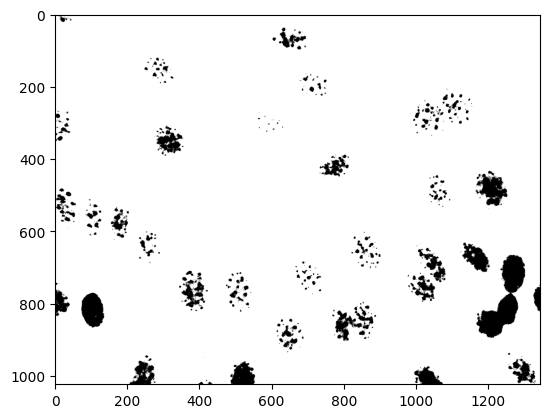

In [ ]:
plt.imshow(img8)
plt.colorbar()
plt.figure()
plt.imshow(img8 < 40, 'gray')

In [ ]:
beispiel1 = np.array([1,5,4,2,3])
beispiel2 = np.array([True, False, True, False, True])

beispiel1[beispiel2]

array([1, 4, 3])

In [ ]:
print(img8.min())

18


In [ ]:
Otsu_values = []
for T in range (img8.min()+1, img8.max()+1):
    class1_intensities = img8[img8 < T]
    class2_intensities = img8[img8 >= T]
    
    class1_bins = h[:T]
    class2_bins = h[T:]

    n1=np.sum(class1_bins)   #gesamtanzahl der pixel in dem bereich der bins
    n2=np.sum(class2_bins)

    var1= np.var(class1_intensities)
    var2 =np.var(class2_intensities)

    O = n1*var1+n2*var2
    Otsu_values.append(O)

optimal_threshold= np.argmin(Otsu_values) + img8.min() +1
print(optimal_threshold)

31


**[Task 1.5.]()** Perform Otsu thresholding:

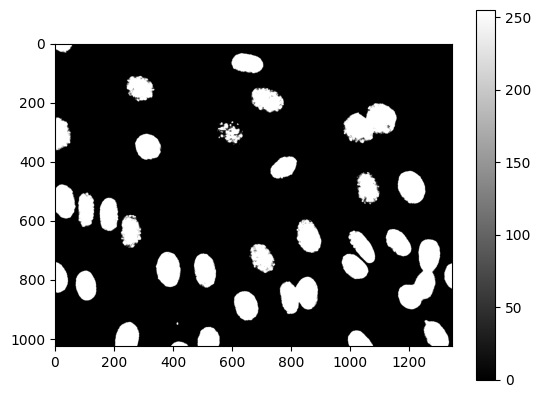

In [ ]:
new_img=img8.copy()
for i in range(new_img.shape[0]):
    for j in range(new_img.shape[1]):
        pixel = new_img[i,j]
        if pixel > optimal_threshold:
            new_img[i,j] =255
        if pixel < optimal_threshold:
            new_img[i,j]=0

plt.imshow(new_img, 'grey')
plt.colorbar()

**[Task 1.6.]()** Compute the Dice coefficient:

In [ ]:
new_img.dtype

dtype('uint8')

In [ ]:
groundtruth = plt.imread('data/NIH3T3/gt/0.png')

In [ ]:
G=groundtruth.astype(bool)
H=new_img.astype(bool)
up= (G*H).sum()*2
down= G.sum()+H.sum()
dice= up/down
print(dice)

0.8943783223933183
